# Notebook 1 — Data Overview & Distributions

Univariate exploration of every feature in the *Student Social Media and Mental Health Impact* dataset (5 000 rows × 13 columns).

## 0. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

# This notebook starts from the raw CSV and exports the cleaned frame to CLEAN_PATH (section 8).
DATA_PATH  = '../dataset/Student Social Media And Mental Health Impact.csv'
CLEAN_PATH = '../dataset/student_social_media_cleaned.csv'
df = pd.read_csv(DATA_PATH)

STRESS_ORDER = ['Low', 'Medium', 'High', 'Very High']
df['Stress_Level'] = pd.Categorical(df['Stress_Level'], categories=STRESS_ORDER, ordered=True)

NUMERIC_COLS = ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
                'Study_Hours', 'Physical_Activity_Hours',
                'Sleep_Hours_Per_Night', 'Mental_Health_Score']
CATEGORICAL_COLS = ['Gender', 'Country', 'Academic_Level',
                    'Most_Used_Platform', 'Purpose_Of_Use']

# --- Cleaning (see section 1 for the checks that motivate it) ---
# 1. The raw CSV contains exact duplicate rows.
n_raw = len(df)
df = df.drop_duplicates().reset_index(drop=True)
N_DUPLICATES_DROPPED = n_raw - len(df)

# 2. A few numeric values are slightly negative (noise around a true value of zero) — clip to 0.
N_NEGATIVES_CLIPPED = int((df[NUMERIC_COLS] < 0).sum().sum())
df[NUMERIC_COLS] = df[NUMERIC_COLS].clip(lower=0)

print(f'Dropped {N_DUPLICATES_DROPPED} duplicate rows ({n_raw} -> {len(df)})')
print(f'Clipped {N_NEGATIVES_CLIPPED} negative values to 0')
print('Shape:', df.shape)
print()
print(df.dtypes)
df.head()

Shape: (5000, 13)

Age                           int64
Gender                       object
Country                      object
Academic_Level               object
Most_Used_Platform           object
Purpose_Of_Use               object
Avg_Daily_Usage_Hours       float64
Daily_Unlocks                 int64
Study_Hours                 float64
Physical_Activity_Hours     float64
Sleep_Hours_Per_Night       float64
Stress_Level               category
Mental_Health_Score         float64
dtype: object


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 1. Data Quality Check

In [2]:
print('=== Missing values per column ===')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.any() else 'No missing values')
print()
print('=== Duplicate rows ===')
print(f'{df.duplicated().sum()} remaining ({N_DUPLICATES_DROPPED} dropped at load)')
print()
print('=== Negative values in numeric columns ===')
print(f'{int((df[NUMERIC_COLS] < 0).sum().sum())} remaining ({N_NEGATIVES_CLIPPED} clipped to 0 at load)')

=== Missing values per column ===
No missing values

=== Duplicate rows ===
2


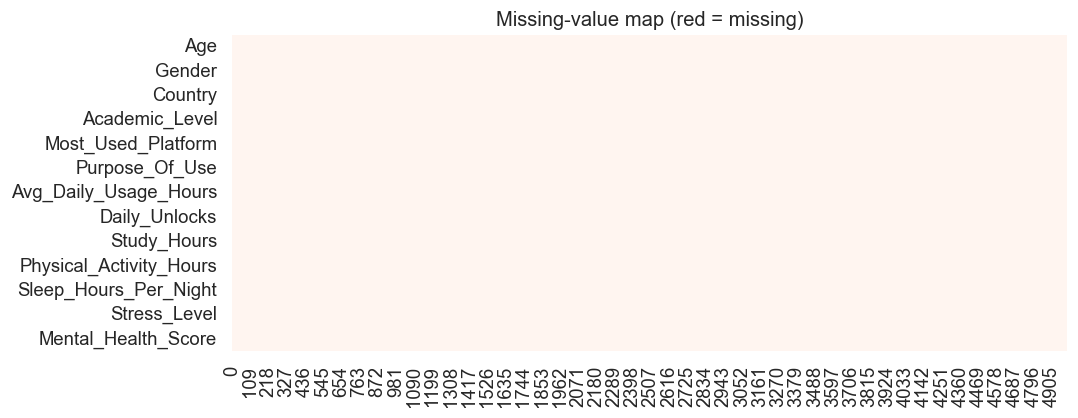

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(
    df.isnull().T,
    cbar=False, yticklabels=True, cmap='Reds',
    ax=ax
)
ax.set_title('Missing-value map (red = missing)')
plt.tight_layout()
plt.show()

In [4]:
print('=== Unique value counts for categorical columns ===')
for col in CATEGORICAL_COLS + ['Stress_Level']:
    print(f'\n{col}:')
    print(df[col].value_counts())

=== Unique value counts for categorical columns ===

Gender:
Gender
Male      2635
Female    2365
Name: count, dtype: int64

Country:
Country
Other        1880
India         389
USA           355
Canada        230
Australia     198
             ... 
Armenia         1
Kuwait          1
Colombia        1
Bosnia          1
Croatia         1
Name: count, Length: 111, dtype: int64

Academic_Level:
Academic_Level
Undergraduate    3632
Graduate          918
High School       450
Name: count, dtype: int64

Most_Used_Platform:
Most_Used_Platform
Instagram    1130
TikTok        918
Facebook      719
LinkedIn      523
YouTube       491
Twitter       462
Snapchat      420
WhatsApp      175
LINE           50
VKontakte      40
KakaoTalk      36
WeChat         36
Name: count, dtype: int64

Purpose_Of_Use:
Purpose_Of_Use
Entertainment    2552
Education        1094
Networking        793
News              561
Name: count, dtype: int64

Stress_Level:
Stress_Level
Very High    1621
High         1440
Mediu

In [5]:
df[NUMERIC_COLS].describe().T.style.format('{:.2f}').background_gradient(cmap='Blues', axis=0)

,count,mean,std,min,25%,50%,75%,max
Age,5000.00,20.82,1.74,18.00,19.00,21.00,22.00,24.00
Avg_Daily_Usage_Hours,5000.00,5.08,1.65,1.00,3.80,5.00,6.30,8.80
Daily_Unlocks,5000.00,171.45,42.86,62.00,140.00,171.00,204.00,273.00
Study_Hours,5000.00,3.01,1.64,0.30,1.50,2.80,4.20,8.30
Physical_Activity_Hours,5000.00,1.75,0.67,-0.40,1.30,1.70,2.20,4.10
Sleep_Hours_Per_Night,5000.00,6.63,1.22,3.60,5.60,6.60,7.50,9.90
Mental_Health_Score,5000.00,6.23,1.28,3.60,5.10,6.10,7.10,9.40


## 2. Numeric Feature Distributions

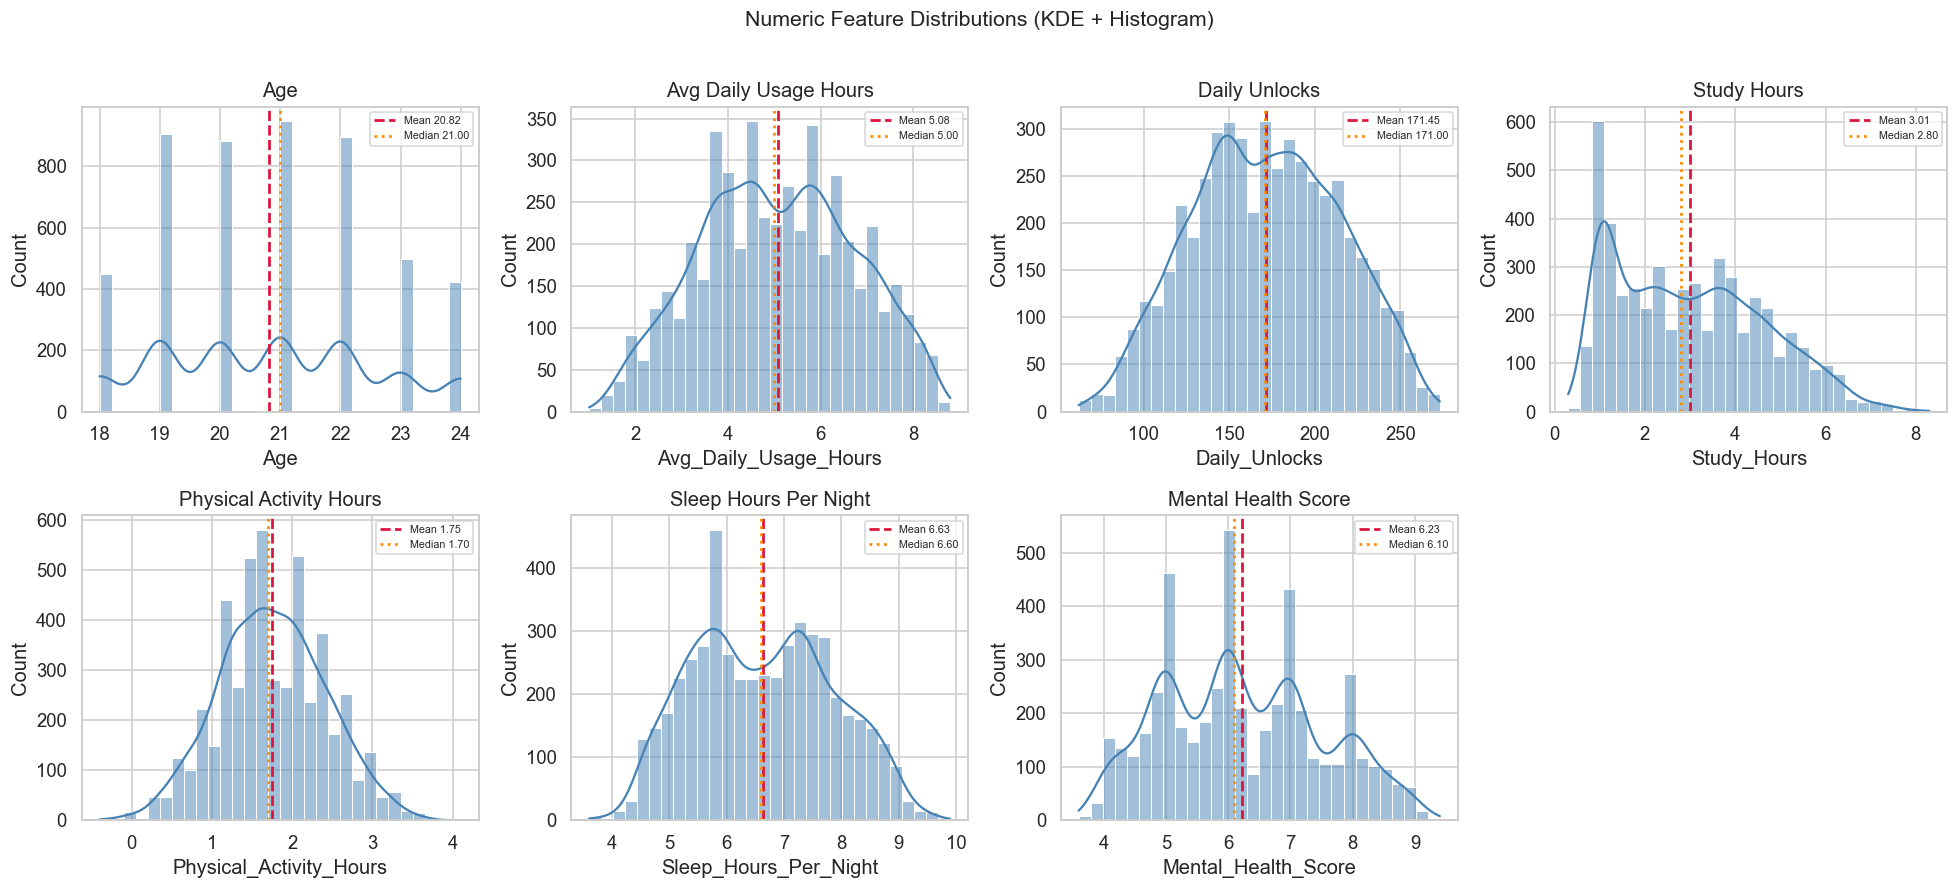

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(NUMERIC_COLS):
    ax = axes[i]
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue', bins=30, edgecolor='white')
    mean_val = df[col].mean()
    median_val = df[col].median()
    ax.axvline(mean_val, color='crimson', lw=1.8, linestyle='--', label=f'Mean {mean_val:.2f}')
    ax.axvline(median_val, color='darkorange', lw=1.8, linestyle=':', label=f'Median {median_val:.2f}')
    ax.set_title(col.replace('_', ' '))
    ax.legend(fontsize=7)

# hide the unused 8th subplot
axes[-1].set_visible(False)

fig.suptitle('Numeric Feature Distributions (KDE + Histogram)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 3. Box-plots for Outlier Detection

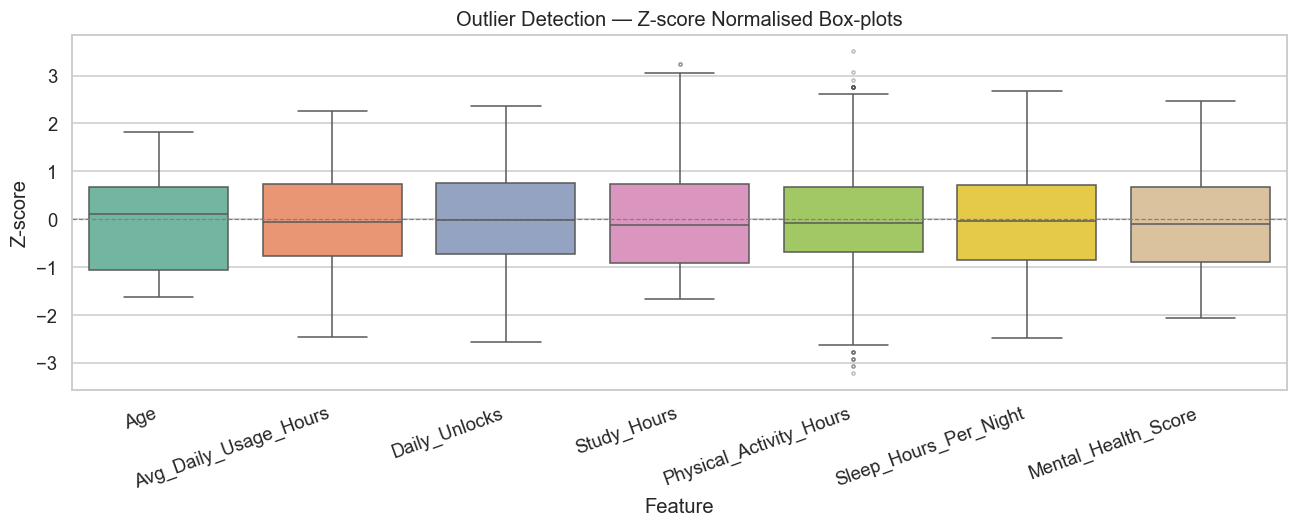

In [7]:
# Z-score normalised box-plots (all features on one axis)
df_z = (df[NUMERIC_COLS] - df[NUMERIC_COLS].mean()) / df[NUMERIC_COLS].std()
df_z_long = df_z.melt(var_name='Feature', value_name='Z-score')

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df_z_long, x='Feature', y='Z-score', ax=ax,
            palette='Set2', flierprops=dict(marker='o', markersize=2, alpha=0.4))
ax.axhline(0, color='grey', lw=0.8, linestyle='--')
ax.set_title('Outlier Detection — Z-score Normalised Box-plots')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
plt.tight_layout()
plt.show()

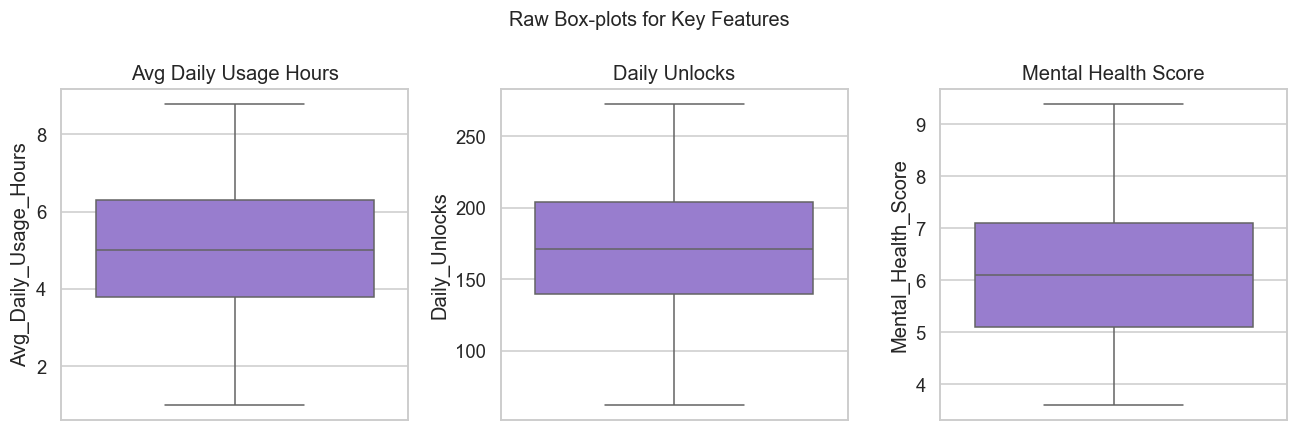

In [8]:
# Raw box-plots for key features
focus_cols = ['Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Mental_Health_Score']
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, focus_cols):
    sns.boxplot(y=df[col], ax=ax, color='mediumpurple',
                flierprops=dict(marker='o', markersize=3, alpha=0.4))
    ax.set_title(col.replace('_', ' '))
fig.suptitle('Raw Box-plots for Key Features', fontsize=13)
plt.tight_layout()
plt.show()

## 4. Categorical Feature Distributions

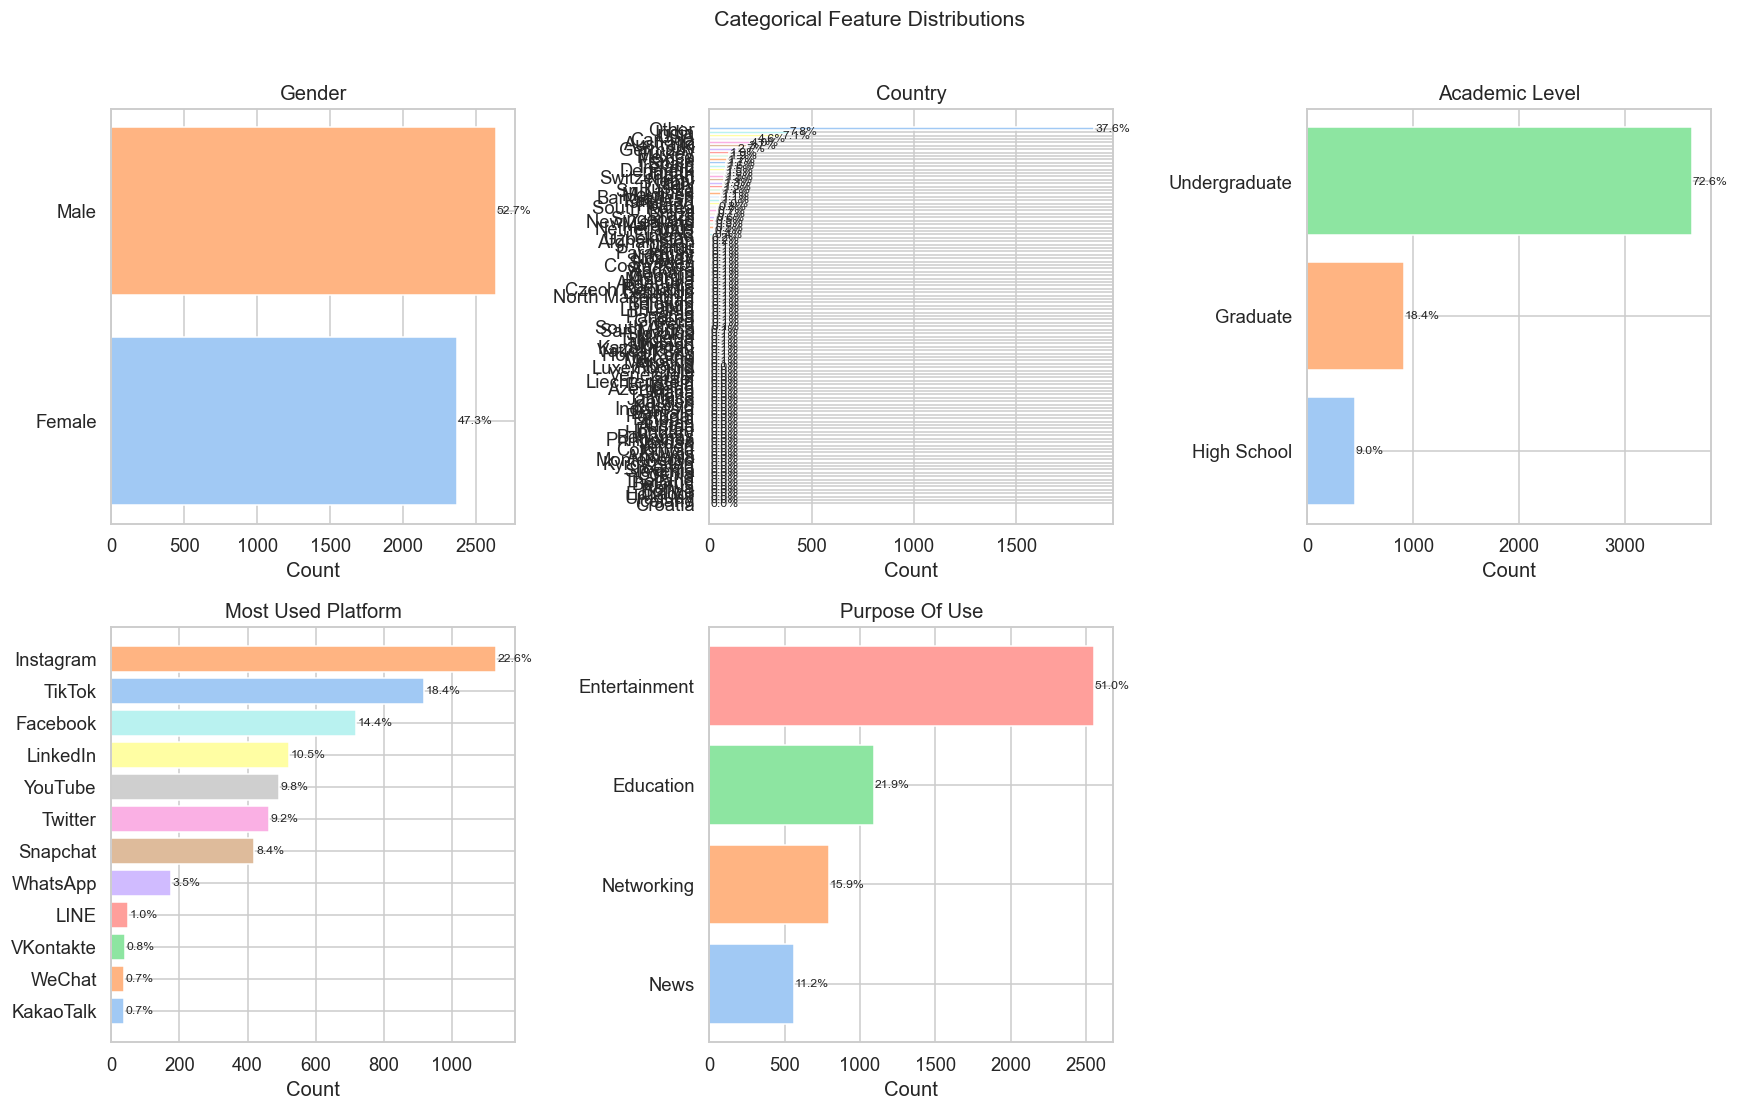

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(CATEGORICAL_COLS):
    ax = axes[i]
    counts = df[col].value_counts().sort_values()
    pcts = counts / len(df) * 100
    bars = ax.barh(counts.index, counts.values, color=sns.color_palette('pastel', len(counts)))
    for bar, pct in zip(bars, pcts.values):
        ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height() / 2,
                f'{pct:.1f}%', va='center', fontsize=8)
    ax.set_title(col.replace('_', ' '))
    ax.set_xlabel('Count')

axes[-1].set_visible(False)
fig.suptitle('Categorical Feature Distributions', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5. Target Variable Deep-Dive — Mental Health Score

**Understanding the p-value.** The Shapiro-Wilk test checks normality; its *null hypothesis* is that the data **is normally distributed**. The **p-value** is the probability of seeing this shape by chance if the data really were normal.

- **p > 0.05** → consistent with **Normal**
- **p ≤ 0.05** → **Not normal**

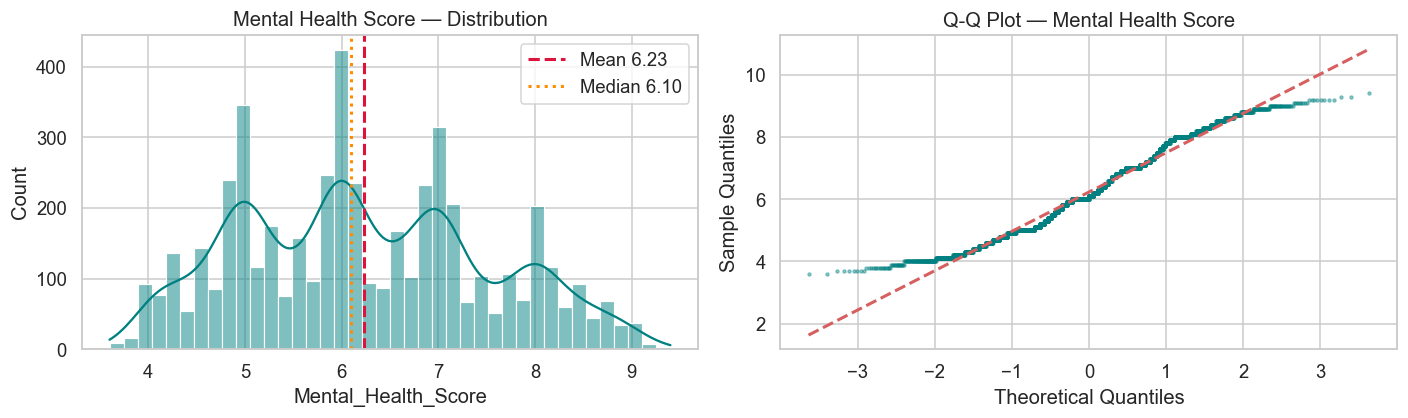

Shapiro-Wilk: W=0.9765, p=6.1770e-28 → Not normal (α=0.05)


In [10]:
target = df['Mental_Health_Score']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram + KDE
ax = axes[0]
sns.histplot(target, kde=True, bins=40, color='teal', edgecolor='white', ax=ax)
ax.axvline(target.mean(), color='crimson', lw=2, linestyle='--', label=f'Mean {target.mean():.2f}')
ax.axvline(target.median(), color='darkorange', lw=2, linestyle=':', label=f'Median {target.median():.2f}')
ax.set_title('Mental Health Score — Distribution')
ax.legend()

# Q-Q plot
ax = axes[1]
res = stats.probplot(target, dist='norm')
ax.scatter(res[0][0], res[0][1], s=4, alpha=0.4, color='teal')
slope, intercept = res[1][0], res[1][1]
x_line = np.array([res[0][0].min(), res[0][0].max()])
ax.plot(x_line, slope * x_line + intercept, 'r--', lw=2)
ax.set_xlabel('Theoretical Quantiles')
ax.set_ylabel('Sample Quantiles')
ax.set_title('Q-Q Plot — Mental Health Score')

plt.tight_layout()
plt.show()

stat, p = stats.shapiro(target.sample(min(5000, len(target)), random_state=42))
print(f'Shapiro-Wilk: W={stat:.4f}, p={p:.4e} → {"Normal" if p > 0.05 else "Not normal"} (α=0.05)')

## 6. Ordinal Feature — Stress Level

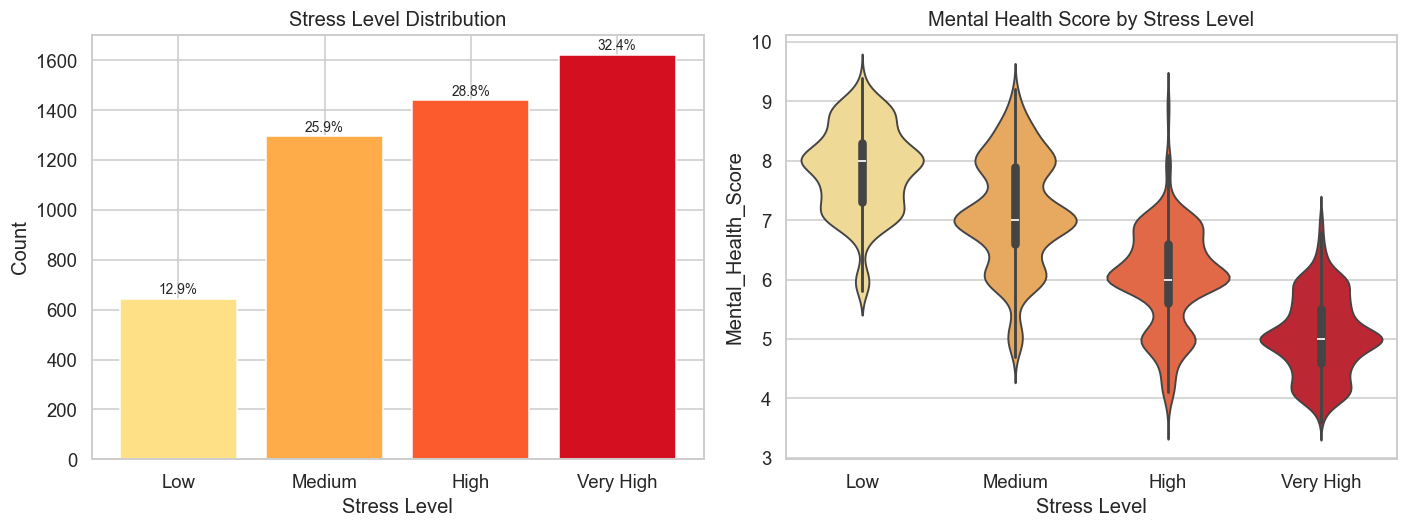

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Ordered bar chart
ax = axes[0]
counts = df['Stress_Level'].value_counts()[STRESS_ORDER]
pcts = counts / len(df) * 100
palette = sns.color_palette('YlOrRd', 4)
bars = ax.bar(STRESS_ORDER, counts.values, color=palette, edgecolor='white')
for bar, pct in zip(bars, pcts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
            f'{pct:.1f}%', ha='center', fontsize=9)
ax.set_title('Stress Level Distribution')
ax.set_xlabel('Stress Level')
ax.set_ylabel('Count')

# Violin plot: Mental Health Score by Stress Level
ax = axes[1]
sns.violinplot(
    data=df, x='Stress_Level', y='Mental_Health_Score',
    order=STRESS_ORDER, palette='YlOrRd', inner='box', ax=ax
)
ax.set_title('Mental Health Score by Stress Level')
ax.set_xlabel('Stress Level')

plt.tight_layout()
plt.show()

## 7. Summary Statistics Table

In [12]:
summary = df[NUMERIC_COLS].agg(['mean', 'std', 'min', 'max']).T
summary['skewness'] = df[NUMERIC_COLS].skew()
summary['kurtosis'] = df[NUMERIC_COLS].kurt()
summary.columns = ['Mean', 'Std', 'Min', 'Max', 'Skewness', 'Kurtosis']
summary.style\
    .format('{:.3f}')\
    .background_gradient(cmap='coolwarm', subset=['Skewness', 'Kurtosis'])\
    .background_gradient(cmap='Blues', subset=['Mean', 'Std'])

,Mean,Std,Min,Max,Skewness,Kurtosis
Age,20.822,1.737,18.000,24.000,0.155,-0.913
Avg_Daily_Usage_Hours,5.078,1.654,1.000,8.800,0.006,-0.768
Daily_Unlocks,171.453,42.858,62.000,273.000,0.002,-0.709
Study_Hours,3.008,1.637,0.300,8.300,0.436,-0.727
Physical_Activity_Hours,1.751,0.668,-0.400,4.100,0.040,-0.226
Sleep_Hours_Per_Night,6.635,1.221,3.600,9.900,0.124,-0.879
Mental_Health_Score,6.231,1.279,3.600,9.400,0.207,-0.803


## 8. Export Cleaned Dataset

The cleaned frame is written to `dataset/student_social_media_cleaned.csv`:

- **exact duplicate rows removed** — 2 pairs in the raw file (5000 → 4998 rows);
- **negative values clipped to 0** — 10 values in `Physical_Activity_Hours`, all between −0.4 and −0.1, i.e. noise around a true value of zero.

Every downstream notebook (`data_exploration/02`, `Questions/01`, `Questions/02`) reads this file instead of the raw CSV, so **re-run this notebook whenever the raw CSV changes**.

In [ ]:
df.to_csv(CLEAN_PATH, index=False)

print(f'Wrote {CLEAN_PATH}')
print(f'  rows x columns     : {df.shape[0]} x {df.shape[1]}')
print(f'  duplicates removed : {N_DUPLICATES_DROPPED}')
print(f'  negatives clipped  : {N_NEGATIVES_CLIPPED}')

# Read the file back and confirm it is actually clean
check = pd.read_csv(CLEAN_PATH)
assert len(check) == len(df), 'row count mismatch'
assert list(check.columns) == list(df.columns), 'column mismatch'
assert check.duplicated().sum() == 0, 'duplicates still present'
assert (check[NUMERIC_COLS] < 0).sum().sum() == 0, 'negative values still present'
print('\nVerified on re-read: no duplicates, no negative values.')